In [2]:
# ============================================================
# NOTEBOOK 02 — NLP TOPIC CLASSIFICATION
# ============================================================
# WHAT ARE WE DOING?
# We use TF-IDF to convert article titles into numbers
# then train a classifier to predict the topic category.

# STEPS:
# 1. Load cleaned data from notebook 01
# 2. Clean and preprocess article titles
# 3. Convert titles to TF-IDF features
# 4. Train a topic classifier
# 5. Evaluate the classifier
# 6. Track everything with MLflow
# 7. Show most important words per category
# ============================================================

print("Starting NLP Topic Classification notebook...")

Starting NLP Topic Classification notebook...


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import re
import os

# TF-IDF converts text to numbers
from sklearn.feature_extraction.text import TfidfVectorizer

# Classifiers to try
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation tools
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported!")

Libraries imported!


In [4]:
# ============================================================
# STEP 1: LOAD CLEANED DATA FROM NOTEBOOK 01
# ============================================================

df = pd.read_csv("../data/processed/news_clean.csv")

print(f"Loaded: {df.shape[0]:,} articles")
print(f"Categories: {df['category_name'].unique().tolist()}")
print()
display(df.head())

Loaded: 422,419 articles
Categories: ['Business', 'Science & Tech', 'Entertainment', 'Health']



,title,category,category_name,publisher,title_length
0,"Fed official says weak data caused by weather,...",b,Business,Los Angeles Times,68
1,Fed's Charles Plosser sees high bar for change...,b,Business,Livemint,66
2,US open: Stocks fall after Fed official hints ...,b,Business,IFA Magazine,69
3,"Fed risks falling 'behind the curve', Charles ...",b,Business,IFA Magazine,58
4,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,b,Business,Moneynews,50


In [5]:
# ============================================================
# STEP 2: CLEAN ARTICLE TITLES
# ============================================================
# Raw titles have noise — special characters, numbers,
# extra spaces. We clean them before feeding to TF-IDF.

def clean_title(text):
    """Clean an article title for NLP processing."""

    # Convert to lowercase — "Apple" and "apple" are the same
    text = text.lower()

    # Remove anything that is not a letter or space
    # This removes numbers, punctuation, special chars
    text = re.sub(r"[^a-z\s]", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply cleaning to all titles
df["title_clean"] = df["title"].apply(clean_title)

print("=== BEFORE vs AFTER CLEANING ===")
for i in range(3):
    print(f"\nOriginal : {df['title'].iloc[i]}")
    print(f"Cleaned  : {df['title_clean'].iloc[i]}")

=== BEFORE vs AFTER CLEANING ===

Original : Fed official says weak data caused by weather, should not slow taper
Cleaned  : fed official says weak data caused by weather should not slow taper

Original : Fed's Charles Plosser sees high bar for change in pace of tapering
Cleaned  : feds charles plosser sees high bar for change in pace of tapering

Original : US open: Stocks fall after Fed official hints at accelerated tapering
Cleaned  : us open stocks fall after fed official hints at accelerated tapering


In [6]:
# ============================================================
# STEP 3: SAMPLE THE DATA FOR FASTER TRAINING
# ============================================================
# 422K articles is a lot for a notebook.
# We sample 50K — still large enough for great results
# but much faster to train and experiment with.

# Sample equally from each category for balance
sample_size_per_category = 12500  # 4 categories x 12500 = 50000

df_sample = df.groupby("category").apply(
    lambda x: x.sample(
        min(len(x), sample_size_per_category),
        random_state=42
    )
).reset_index(drop=True)

print(f"Sample size: {len(df_sample):,} articles")
print()
print("Articles per category:")
print(df_sample["category_name"].value_counts())

Sample size: 50,000 articles

Articles per category:
category_name
Business          12500
Entertainment     12500
Health            12500
Science & Tech    12500
Name: count, dtype: int64


/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79429/2248917805.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df.groupby("category").apply(


In [7]:
# ============================================================
# STEP 4: TF-IDF VECTORIZATION
# ============================================================
# TF-IDF converts each title into a vector of numbers.
# Each number represents how important a word is
# for that article compared to all other articles.

# Split into features (X) and labels (y)
X = df_sample["title_clean"]  # article titles
y = df_sample["category"]     # category labels (b, t, e, m)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 80% train, 20% test
    random_state=42,
    stratify=y          # keep same category ratio in both sets
)

print(f"Train size: {len(X_train):,}")
print(f"Test size : {len(X_test):,}")
print()

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,   # keep top 10,000 words only
    ngram_range=(1, 2),   # use single words AND two-word phrases
    stop_words="english", # remove common words like "the", "is"
    min_df=2              # ignore words appearing in only 1 article
)

# Fit on training data and transform both sets
# IMPORTANT: fit only on train — never on test!
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF matrix shape: {X_train_tfidf.shape}")
print(f"Each article = vector of {X_train_tfidf.shape[1]:,} numbers")

Train size: 40,000
Test size : 10,000

TF-IDF matrix shape: (40000, 10000)
Each article = vector of 10,000 numbers


In [8]:
# ============================================================
# STEP 5: TRAIN CLASSIFIER WITH MLFLOW TRACKING
# ============================================================

# Set MLflow experiment name
mlflow.set_experiment("newslens-topic-classification")

# Category mapping for readable reports
category_map = {
    "b": "Business",
    "t": "Science & Tech",
    "e": "Entertainment",
    "m": "Health"
}

def train_and_log(model, model_name, params):
    """Train a model and log everything to MLflow."""

    with mlflow.start_run(run_name=model_name):

        # Log hyperparameters
        mlflow.log_params(params)

        # Train the model
        model.fit(X_train_tfidf, y_train)

        # Predict on test set
        y_pred = model.predict(X_test_tfidf)

        # Calculate accuracy
        accuracy = accuracy_score(y_test, y_pred)

        # Log accuracy to MLflow
        mlflow.log_metric("accuracy", accuracy)

        # Save the model to MLflow
        mlflow.sklearn.log_model(model, artifact_path="model")

        print(f"\n{model_name}")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"\n{classification_report(y_test, y_pred, target_names=list(category_map.values()))}")

        return model, y_pred, accuracy

# --- Model 1: Logistic Regression ---
lr_params = {"C": 1.0, "max_iter": 1000, "solver": "lbfgs"}
lr_model = LogisticRegression(**lr_params, multi_class="multinomial")
lr_model, lr_preds, lr_acc = train_and_log(
    lr_model, "LogisticRegression", lr_params
)

# --- Model 2: Random Forest ---
rf_params = {"n_estimators": 100, "max_depth": 20, "random_state": 42}
rf_model = RandomForestClassifier(**rf_params)
rf_model, rf_preds, rf_acc = train_and_log(
    rf_model, "RandomForest", rf_params
)

2026/10/23 13:05:27 INFO mlflow.tracking.fluent: Experiment with name 'newslens-topic-classification' does not exist. Creating a new experiment.
/Users/haritharetnakaran/Documents/Personal_projects/newslens-publishing-intelligence/venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
2026/10/23 13:05:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:05:31 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



LogisticRegression
  Accuracy: 0.9068

                precision    recall  f1-score   support

      Business       0.87      0.88      0.87      2500
Science & Tech       0.93      0.95      0.94      2500
 Entertainment       0.93      0.93      0.93      2500
        Health       0.90      0.87      0.89      2500

      accuracy                           0.91     10000
     macro avg       0.91      0.91      0.91     10000
  weighted avg       0.91      0.91      0.91     10000



2026/10/23 13:05:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:05:34 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



RandomForest
  Accuracy: 0.6978

                precision    recall  f1-score   support

      Business       0.47      0.90      0.62      2500
Science & Tech       0.89      0.64      0.74      2500
 Entertainment       0.91      0.65      0.76      2500
        Health       0.89      0.60      0.72      2500

      accuracy                           0.70     10000
     macro avg       0.79      0.70      0.71     10000
  weighted avg       0.79      0.70      0.71     10000



Best model: LogisticRegression (accuracy: 0.9068)


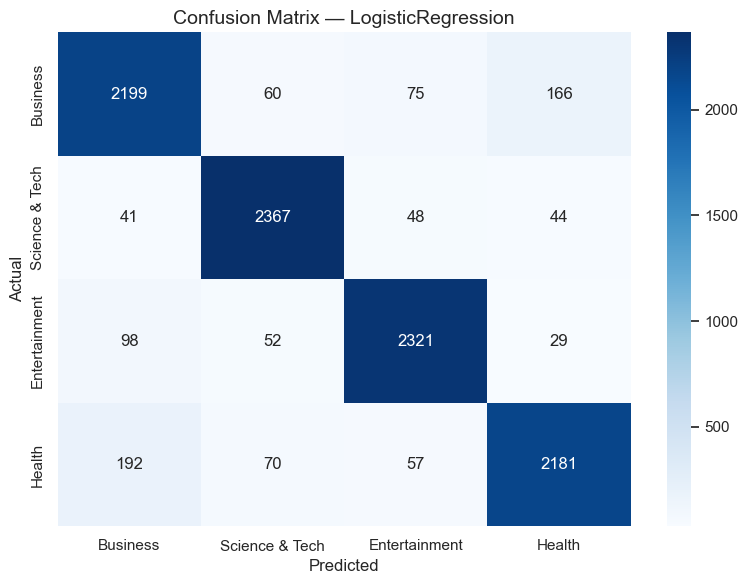

Confusion matrix saved!


In [9]:
# ============================================================
# STEP 6: CONFUSION MATRIX FOR BEST MODEL
# ============================================================

# Pick the best model
best_model = lr_model if lr_acc > rf_acc else rf_model
best_preds = lr_preds if lr_acc > rf_acc else rf_preds
best_name = "LogisticRegression" if lr_acc > rf_acc else "RandomForest"

print(f"Best model: {best_name} (accuracy: {max(lr_acc, rf_acc):.4f})")

# Plot confusion matrix
cm = confusion_matrix(y_test, best_preds)
labels = list(category_map.values())

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f"Confusion Matrix — {best_name}", fontsize=14)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("../data/processed/nlp_confusion_matrix.png")
plt.show()
print("Confusion matrix saved!")

/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79429/2098057554.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_words, palette="Blues_d", ax=ax)
/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79429/2098057554.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_words, palette="Blues_d", ax=ax)
/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79429/2098057554.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_words, palette="Blues_d", ax=ax)
/

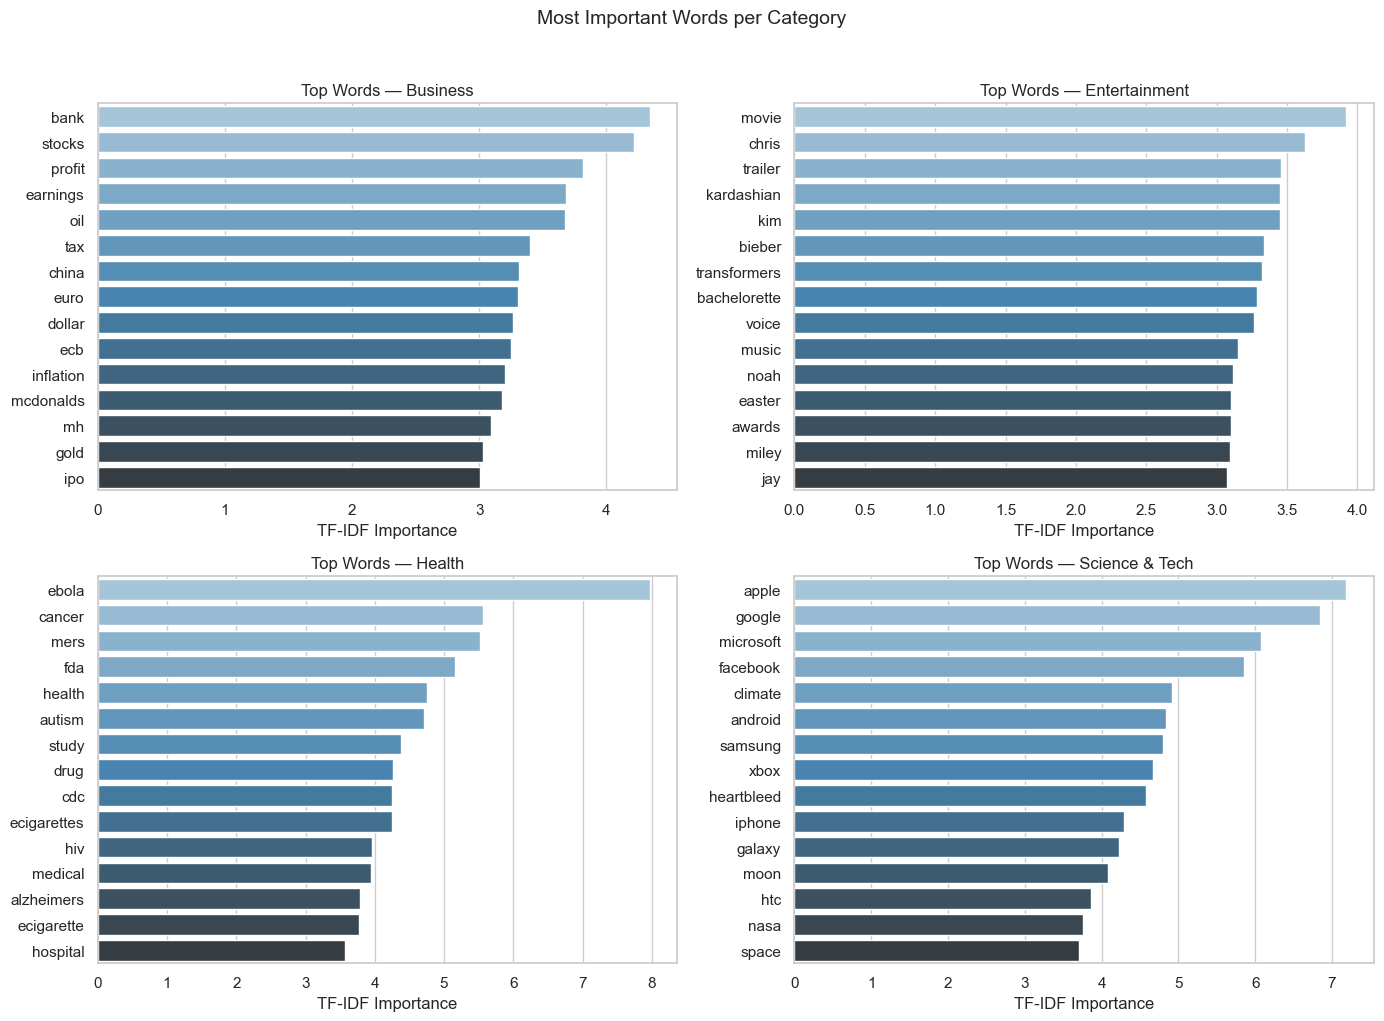

Top words chart saved!


In [10]:
# ============================================================
# STEP 7: TOP WORDS PER CATEGORY
# ============================================================
# This is very useful for editorial teams!
# It shows WHICH words define each category.
# Upscore uses this kind of analysis for content strategy.

# Get feature names from TF-IDF
feature_names = tfidf.get_feature_names_out()

# Get the coefficients from Logistic Regression
# Each category has a coefficient per word
# Higher coefficient = more important for that category
coefficients = lr_model.coef_

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

categories = lr_model.classes_

for i, (cat_code, ax) in enumerate(zip(categories, axes)):

    cat_name = category_map[cat_code]

    # Get top 15 words for this category
    top_indices = coefficients[i].argsort()[-15:][::-1]
    top_words = [feature_names[j] for j in top_indices]
    top_scores = [coefficients[i][j] for j in top_indices]

    # Plot
    sns.barplot(x=top_scores, y=top_words, palette="Blues_d", ax=ax)
    ax.set_title(f"Top Words — {cat_name}", fontsize=12)
    ax.set_xlabel("TF-IDF Importance")

plt.suptitle("Most Important Words per Category", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/top_words_per_category.png")
plt.show()
print("Top words chart saved!")

In [11]:
# ============================================================
# STEP 8: TEST WITH NEW HEADLINES
# ============================================================
# Let's classify some brand new headlines!

new_headlines = [
    "Federal Reserve raises interest rates again",
    "New cancer treatment shows promising results",
    "Apple announces new MacBook with AI features",
    "Taylor Swift breaks streaming record on Spotify"
]

# Clean and vectorize new headlines
new_clean = [clean_title(h) for h in new_headlines]
new_tfidf = tfidf.transform(new_clean)

# Predict categories
predictions = best_model.predict(new_tfidf)

print("=== CLASSIFYING NEW HEADLINES ===\n")
for headline, pred in zip(new_headlines, predictions):
    print(f"Headline : {headline}")
    print(f"Category : {category_map[pred]}")
    print()

=== CLASSIFYING NEW HEADLINES ===

Headline : Federal Reserve raises interest rates again
Category : Business

Headline : New cancer treatment shows promising results
Category : Health

Headline : Apple announces new MacBook with AI features
Category : Science & Tech

Headline : Taylor Swift breaks streaming record on Spotify
Category : Entertainment



In [12]:
# ============================================================
# STEP 9: SAVE MODEL AND VECTORIZER FOR LATER USE
# ============================================================
import pickle

os.makedirs("../data/processed", exist_ok=True)

# Save the TF-IDF vectorizer
with open("../data/processed/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

# Save the best classifier
with open("../data/processed/topic_classifier.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Saved TF-IDF vectorizer → data/processed/tfidf_vectorizer.pkl")
print("Saved topic classifier  → data/processed/topic_classifier.pkl")

Saved TF-IDF vectorizer → data/processed/tfidf_vectorizer.pkl
Saved topic classifier  → data/processed/topic_classifier.pkl


In [14]:
# ============================================================
# SUMMARY — WHAT DID WE LEARN?
# ============================================================

print("=== NLP TOPIC CLASSIFICATION SUMMARY ===")
print(f"Best model    : {best_name}")
print(f"Accuracy      : {max(lr_acc, rf_acc):.4f}")
print(f"TF-IDF vocab  : 10,000 features")
print(f"Training size : {len(X_train):,} articles")

print("""
WHAT HAPPENS NEXT?
------------------
We can now classify any news article automatically!

Next we simulate reader behaviour and build a
CHURN PREDICTION model — predicting which readers
are about to cancel their subscription.

See notebook 03_churn.ipynb!
""")

=== NLP TOPIC CLASSIFICATION SUMMARY ===
Best model    : LogisticRegression
Accuracy      : 0.9068
TF-IDF vocab  : 10,000 features
Training size : 40,000 articles

WHAT HAPPENS NEXT?
------------------
We can now classify any news article automatically!

Next we simulate reader behaviour and build a
CHURN PREDICTION model — predicting which readers
are about to cancel their subscription.

See notebook 03_churn.ipynb!

